# Zgodność anotatorów: iteracja 1 vs iteracja 2

Fleiss κ liczony dla tych samych dwóch osób (sędzia nie jest niezależnym anotatorem, więc go nie wliczamy).

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import cohen_kappa_score, confusion_matrix

ITERATIONS = {
    "iteracja 1": ("annotations/igor-annotations.json", "annotations/kacper-annotations.json"),
    "iteracja 2": ("annotations/igor-annotations-2.json", "annotations/kacper-annotations-2.json"),
}
FIELDS = {"stance": ["popiera", "neutralna", "sprzeciwia się"], "ton": ["zwykły", "agresywny"]}


def load(path):
    return {t["text"]: t for t in json.load(open(path))}


data = {}
for it, (a, b) in ITERATIONS.items():
    igor, kacper = load(a), load(b)
    data[it] = [(igor[t], kacper[t]) for t in igor if t in kacper]
    print(it, len(data[it]), "wspólnych tekstów")

iteracja 1 49 wspólnych tekstów
iteracja 2 50 wspólnych tekstów


## Kappa

In [2]:
def fleiss_kappa(*raters):
    labels = np.column_stack(raters)
    counts = np.stack([(labels == c).sum(axis=1) for c in np.unique(labels)], axis=1)
    n = labels.shape[1]
    p_j = counts.sum(axis=0) / counts.sum()
    P_i = ((counts**2).sum(axis=1) - n) / (n * (n - 1))
    return (P_i.mean() - (p_j**2).sum()) / (1 - (p_j**2).sum())


rows = []
for it, pairs in data.items():
    for field in FIELDS:
        a, b = [i[field] for i, _ in pairs], [k[field] for _, k in pairs]
        rows.append({"iteracja": it, "etykieta": field, "Cohen κ": cohen_kappa_score(a, b), "Fleiss κ": fleiss_kappa(a, b)})
kappa = pd.DataFrame(rows)
kappa.pivot(index="etykieta", columns="iteracja", values=["Cohen κ", "Fleiss κ"]).round(3)

Cohen κ              Fleiss κ           
iteracja iteracja 1 iteracja 2 iteracja 1 iteracja 2
etykieta                                            
stance        0.572      0.937      0.570      0.937
ton           0.652      0.793      0.648      0.792

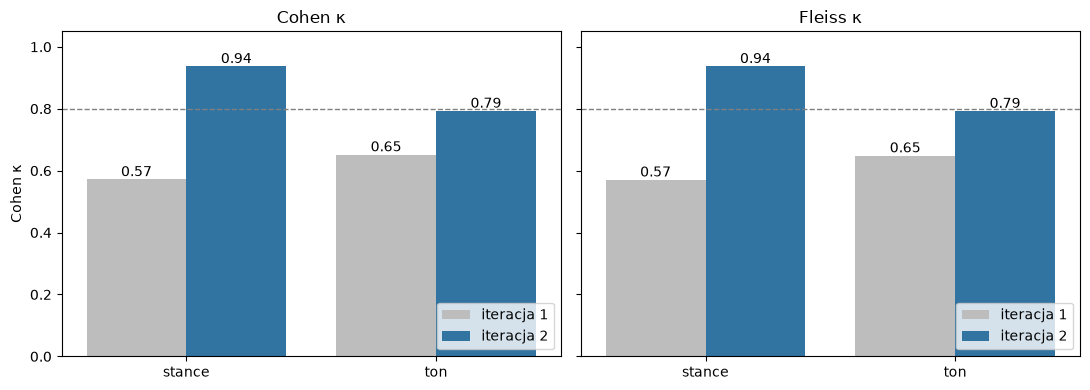

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, metric in zip(axes, ["Cohen κ", "Fleiss κ"]):
    sns.barplot(kappa, x="etykieta", y=metric, hue="iteracja", ax=ax, palette=["#bdbdbd", "#1f77b4"])
    for c in ax.containers:
        ax.bar_label(c, fmt="%.2f")
    ax.axhline(0.8, ls="--", c="gray", lw=1)
    ax.set(ylim=(0, 1.05), title=metric, xlabel="")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Macierze pomyłek (wiersze: Igor, kolumny: Kacper)

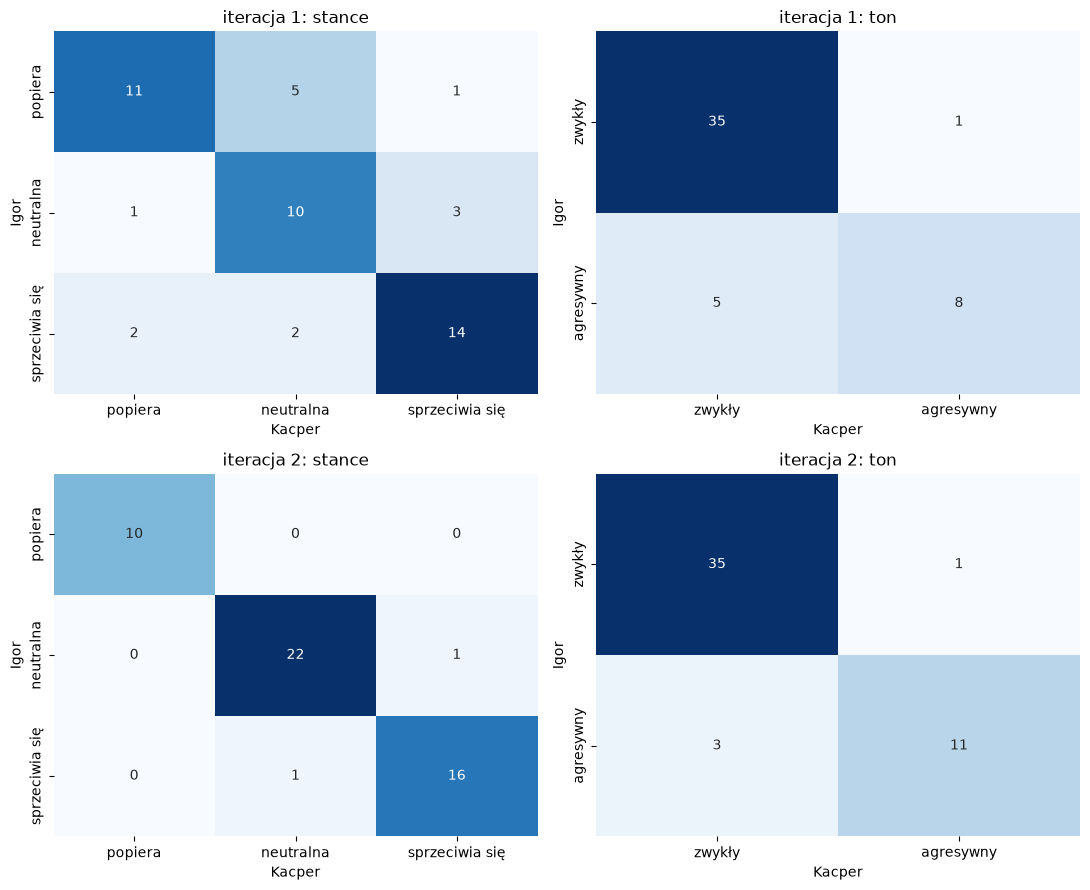

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for row, (it, pairs) in zip(axes, data.items()):
    for ax, (field, labels) in zip(row, FIELDS.items()):
        cm = confusion_matrix([i[field] for i, _ in pairs], [k[field] for _, k in pairs], labels=labels)
        sns.heatmap(cm, annot=True, cmap="Blues", cbar=False, xticklabels=labels, yticklabels=labels, ax=ax)
        ax.set(title=f"{it}: {field}", xlabel="Kacper", ylabel="Igor")
plt.tight_layout()
plt.show()

## F1 dla fragmentów (Igor = gold standard, span trafiony, jeśli nakłada się na span Igora o tej samej etykiecie)

iteracja,iteracja 1,iteracja 2
etykieta,,
Agresja,0.368,0.854
Kontekst,0.404,0.750


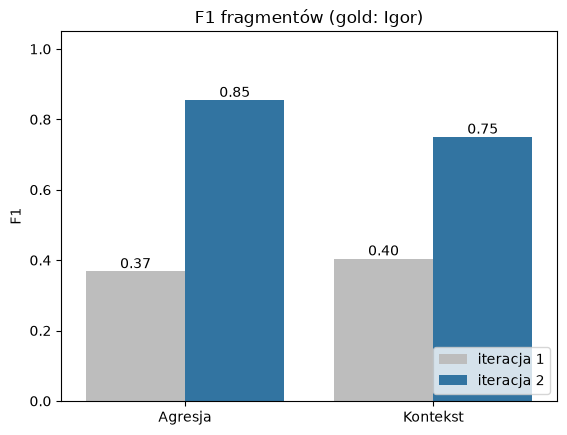

In [5]:
def spans(task, label):
    return [(s["start"], s["end"]) for s in task.get("spans") or [] if label in s["labels"]]


def span_f1(pairs, label):
    gold = [(i, s) for i, (g, _) in enumerate(pairs) for s in spans(g, label)]
    pred = [(i, s) for i, (_, p) in enumerate(pairs) for s in spans(p, label)]
    hit = lambda x, ys: any(x[0] == y[0] and x[1][0] < y[1][1] and y[1][0] < x[1][1] for y in ys)
    precision = np.mean([hit(p, gold) for p in pred])
    recall = np.mean([hit(g, pred) for g in gold])
    return 2 * precision * recall / (precision + recall)


f1 = pd.DataFrame([{"iteracja": it, "etykieta": label, "F1": span_f1(pairs, label)}
                   for it, pairs in data.items() for label in ("Agresja", "Kontekst")])
display(f1.pivot(index="etykieta", columns="iteracja", values="F1").round(3))

ax = sns.barplot(f1, x="etykieta", y="F1", hue="iteracja", palette=["#bdbdbd", "#1f77b4"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f")
ax.set(ylim=(0, 1.05), xlabel="", title="F1 fragmentów (gold: Igor)")
ax.legend(loc="lower right")
plt.show()

## Wniosek

Po aktualizacji wytycznych zgodność wzrosła we wszystkich miarach:

| | iteracja 1 | iteracja 2 |
|---|---|---|
| stance, Cohen κ | 0,57 | 0,94 |
| ton, Cohen κ | 0,65 | 0,79 |
| F1 spanów Agresja | 0,37 | 0,85 |
| F1 spanów Kontekst | 0,40 | 0,75 |

W iteracji 1 najwięcej rozbieżności dotyczyło granicy *popiera / neutralna* oraz tekstów, które Igor uznał za agresywne, a Kacper za zwykłe. W iteracji 2 zostały pojedyncze przypadki.